
# Lab 7: Fast Fourier Transform (FFT)

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


 **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.


## Example 1: Sonido musical Do mayor

Cargamos el archivo Nota_CM_piano.mp3 y primero observamos la señal en el tiempo. Después calculamos la FFT con NumPy y SciPy y comparamos los resultados.

In [4]:
# Librery
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from PIL import Image
from scipy.fft import fft, fftfreq, fft2, ifft2, fftshift
from scipy.signal import find_peaks

plt.rcParams['figure.figsize'] = (10, 4)

ModuleNotFoundError: No module named 'pandas'

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Frecuencia de muestreo: 44100 Hz
Número de datos: 152064
Duración: 3.4481632653061225 s


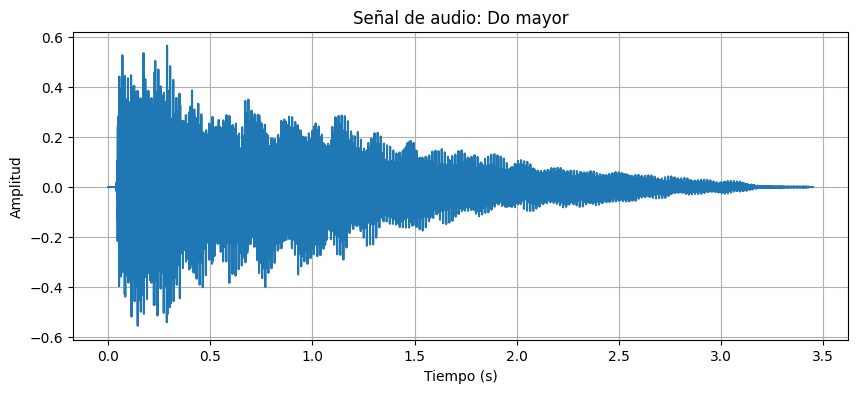

In [ ]:
# Cargar el archivo de audio
signal, sr = librosa.load('Nota_CM_piano.mp3', sr=None)
signal = np.array(signal, dtype=float)

# Tiempo de cada dato
t = np.arange(len(signal))/sr

print('Frecuencia de muestreo:', sr, 'Hz')
print('Número de datos:', len(signal))
print('Duración:', len(signal)/sr, 's')

plt.figure(figsize=(10,4))
plt.plot(t, signal)
plt.title('Señal de audio: Do mayor')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

### 1. FFT con NumPy y SciPy

La FFT permite ver las frecuencias que componen el sonido. Como el resultado tiene frecuencias positivas y negativas, para identificar los tonos mostramos también solo la mitad positiva del espectro.

Error máximo entre NumPy y SciPy: 5.084229945850415e-13
¿Los resultados son iguales? True


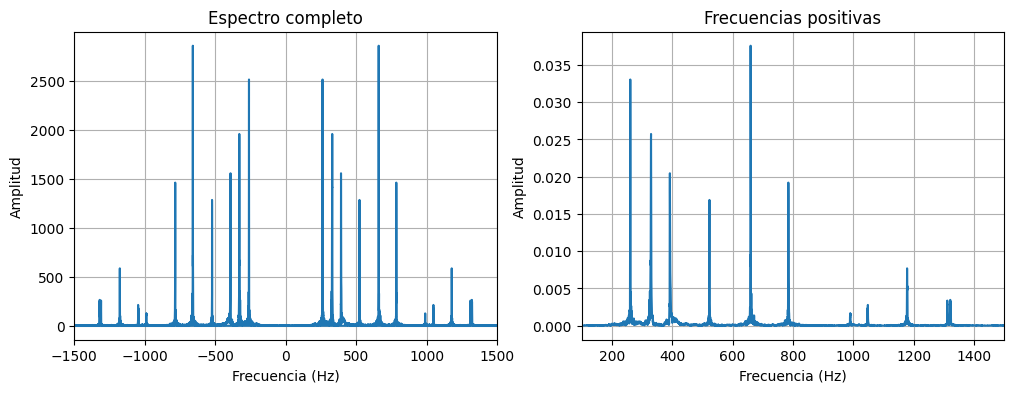

In [ ]:
# FFT usando NumPy y SciPy
N = len(signal)
yf_np = np.fft.fft(signal)
yf_scipy = fft(signal)
xf = fftfreq(N, 1/sr)

# Comparar los resultados de las dos librerias
error_fft = np.max(np.abs(yf_np-yf_scipy))
print('Error máximo entre NumPy y SciPy:', error_fft)

# Espectro de frecuencias positivas
frecuencias = xf[:N//2]
amplitud = 2.0/N*np.abs(yf_scipy[:N//2])

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(xf, np.abs(yf_scipy))
plt.title('Espectro completo')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(-1500,1500)
plt.grid()

plt.subplot(1,2,2)
plt.plot(frecuencias, amplitud)
plt.title('Frecuencias positivas')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(100,1500)
plt.grid()
plt.show()

Buscar los picos más altos del espectro. Estos picos indican las frecuencias que tienen mayor presencia en el sonido. También aparecen armónicos, así que no todos los picos corresponden a una nota fundamental diferente.

Frecuencias principales:
659.48 Hz -> 0.037576
261.01 Hz -> 0.033041
329.74 Hz -> 0.025733
392.09 Hz -> 0.020458
784.48 Hz -> 0.019204
523.18 Hz -> 0.01688
1177.73 Hz -> 0.007699
2110.69 Hz -> 0.006563
1990.04 Hz -> 0.006517
1971.48 Hz -> 0.006119


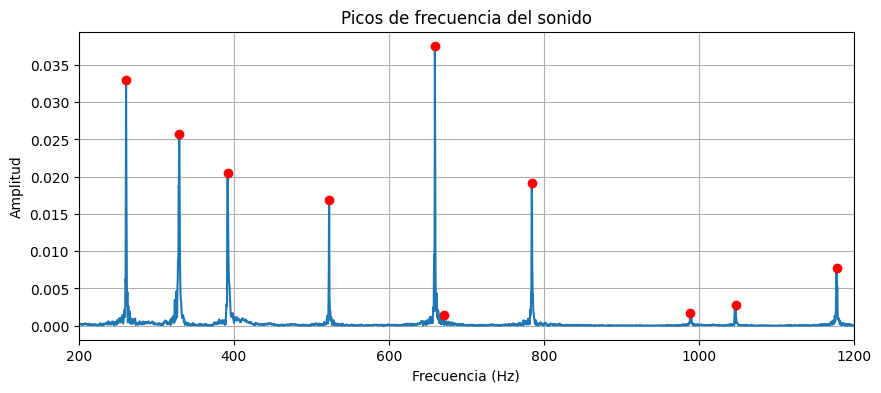

In [ ]:
# Buscar los picos del espectro
paso_f = sr/N
picos, propiedades = find_peaks(amplitud,
                                height=np.max(amplitud)*0.03,
                                prominence=np.max(amplitud)*0.02,
                                distance=max(1, int(10/paso_f)))

orden = np.argsort(amplitud[picos])[::-1]
print('Frecuencias principales:')
for i in orden[:10]:
    print(round(frecuencias[picos[i]],2), 'Hz ->', round(amplitud[picos[i]],6))

plt.figure(figsize=(10,4))
plt.plot(frecuencias, amplitud)
plt.plot(frecuencias[picos], amplitud[picos], 'ro')
plt.xlim(200,1200)
plt.title('Picos de frecuencia del sonido')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

### 2. Transformada usando la rutina FT(x,y) de clase

En clase la rutina usa la función base

$$g(t,w)=\frac{1}{2\pi}e^{-i2\pi wt}.$$

  El código de clase interpola los datos y calcula una integral. Acá aproxima la integral con una suma y se le pasa el vector de frecuencias que se va revisar

In [ ]:
# Base de Fourier que se vio en clase
def g(t,w):
    return 1.0/(2*np.pi)*np.exp(-1j*2*np.pi*w*t)

#  FT  para datos discretos
def FT(x,y,w):
    dx = x[1]-x[0]
    df = []
    for i in range(len(w)):
        Fw = np.sum(y*g(x,w[i]))*dx
        ARew = Fw.real
        AImw = Fw.imag
        AMP = np.sqrt(ARew**2 + AImw**2)
        ANG = np.arctan2(AImw,ARew)
        df.append([w[i], ARew, AImw, AMP, ANG])

    df = pd.DataFrame(df, columns=['w','ReTw','ImTw','AMP','ANG'])
    return df

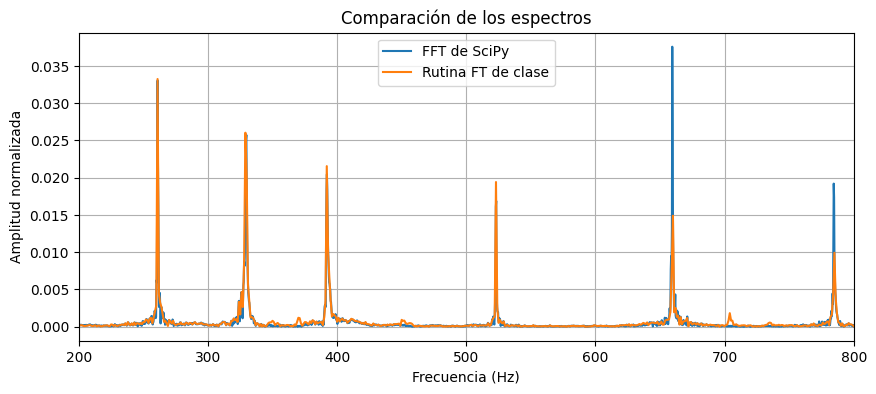

Picos de la rutina FT:
261.0 Hz -> 0.033243
329.0 Hz -> 0.026036
392.0 Hz -> 0.02155
523.0 Hz -> 0.019418
660.0 Hz -> 0.014894
785.0 Hz -> 0.009923
704.0 Hz -> 0.001824
370.0 Hz -> 0.0012
671.0 Hz -> 0.001173


In [ ]:

factor = 10
x_FT = t[::factor]
y_FT = signal[::factor]
w = np.linspace(200,800,601)

df = FT(x_FT, y_FT, w)

# Ajustar la escala para comparar con el espectro normalizado de la FFT
dt = x_FT[1]-x_FT[0]
df['AMP_norm'] = df.AMP*4*np.pi/(len(y_FT)*dt)

plt.figure(figsize=(10,4))
plt.plot(frecuencias, amplitud, label='FFT de SciPy')
plt.plot(df.w, df.AMP_norm, label='Rutina FT de clase')
plt.xlim(200,800)
plt.title('Comparación de los espectros')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud normalizada')
plt.legend()
plt.grid()
plt.show()

# Frecuencias principales encontradas
picos_FT, propiedades_FT = find_peaks(df.AMP_norm,
                                      prominence=np.max(df.AMP_norm)*0.02,
                                      height=np.max(df.AMP_norm)*0.03,
                                      distance=10)
orden_FT = np.argsort(df.AMP_norm.values[picos_FT])[::-1]
print('Picos de la rutina FT:')
for i in orden_FT[:10]:
    print(round(df.w.values[picos_FT[i]],2), 'Hz ->', round(df.AMP_norm.values[picos_FT[i]],6))

**Conclusión del ejemplo:** NumPy y SciPy producen el mismo resultado para la FFT. La rutina FT también muestra picos en las mismas zonas de frecuencia. Puede haber pequeñas diferencias en las amplitudes porque la función usa una aproximación por suma, se tomaron menos muestras y se ajustó la normalización para comparar los espectros.

## Exercise 1: FFT de una imagen

Para el ejercicio uso la imagen del gato. Primero la paso a escala de grises y la reduzco a una matriz de 96 x 96 píxeles para que la transformada directa hecha con la rutina de clase se pueda calcular en un tiempo razonable. La FFT de SciPy también se calcula sobre esa misma matriz.

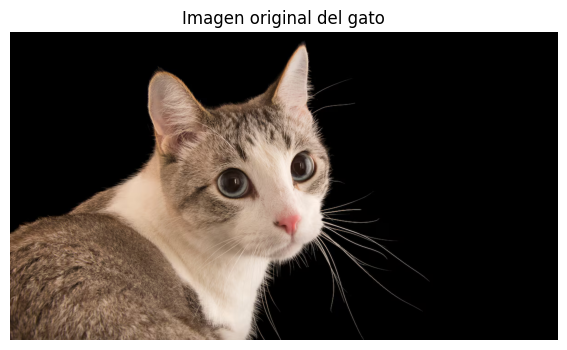

Tamaño de la matriz de la imagen: (96, 96)


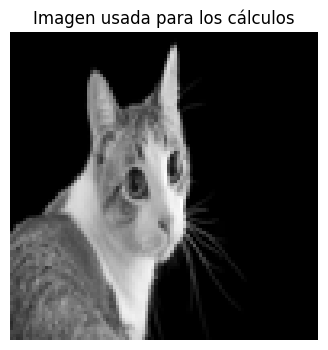

In [ ]:
imagen_color = Image.open('imagen_gato.png').convert('RGB')
plt.figure(figsize=(8,4))
plt.imshow(imagen_color)
plt.title('Imagen original del gato')
plt.axis('off')
plt.show()

# Convertir a escala de grises y reducir el tamaño
imagen_gris = Image.open('imagen_gato.png').convert('L')
imagen_gris = imagen_gris.resize((96,96))
imagen = np.array(imagen_gris, dtype=float)/255.0

print('Tamaño de la matriz de la imagen:', imagen.shape)
plt.figure(figsize=(4,4))
plt.imshow(imagen, cmap='gray')
plt.title('Imagen usada para los cálculos')
plt.axis('off')
plt.show()

### 1. FFT de la imagen con SciPy

En una imagen, la transformada se aplica en dos dimensiones. La magnitud del espectro muestra cómo se distribuyen las frecuencias espaciales.

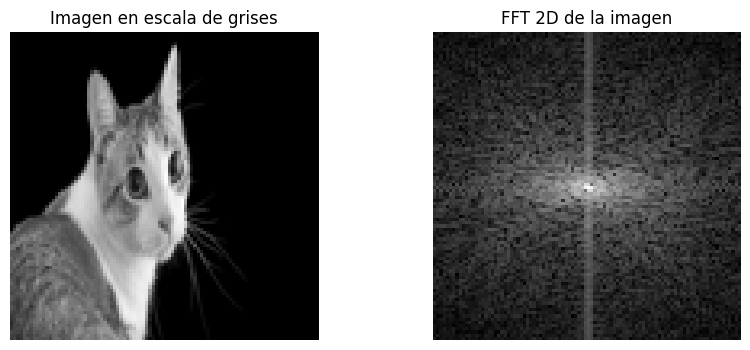

In [ ]:
#  Fourier 2D con SciPy
F_scipy = fft2(imagen)
F_scipy_centro = fftshift(F_scipy)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen en escala de grises')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(np.log(1+np.abs(F_scipy_centro)), cmap='gray')
plt.title('FFT 2D de la imagen')
plt.axis('off')
plt.show()

### 2. Transformada de Fourier usando la rutina de clase

Para aplicarla a la imagen se hace la transformada de cada fila y después la de cada columna. Es la misma rutina FT(x,y,w), aplicada dos veces. La función "g" de clase tiene el factor 1/(2*pi), por lo que al comparar con fft2 se compensa ese factor en las dos dimensiones.

In [ ]:

def FT2D(im):
    Nx, Ny = im.shape
    x = np.arange(Nx)
    y = np.arange(Ny)
    wx = np.fft.fftfreq(Nx, d=1)
    wy = np.fft.fftfreq(Ny, d=1)

    F1 = np.zeros((Nx,Ny), dtype=complex)
    for i in range(Nx):
        df_fila = FT(y, im[i,:], wy)
        F1[i,:] = df_fila.ReTw.values + 1j*df_fila.ImTw.values

    F2 = np.zeros((Nx,Ny), dtype=complex)
    for j in range(Ny):
        df_columna = FT(x, F1[:,j], wx)
        F2[:,j] = df_columna.ReTw.values + 1j*df_columna.ImTw.values

    return F2

F_clase = FT2D(imagen)

# normalización para compararla con fft2
F_clase_comparar = F_clase*(2*np.pi)**2
error_relativo = np.max(np.abs(F_clase_comparar-F_scipy))/np.max(np.abs(F_scipy))
print('Error relativo entre FT de clase y SciPy:', error_relativo)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(np.log(1+np.abs(fftshift(F_scipy))), cmap='gray')
plt.title('FFT de SciPy')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(np.log(1+np.abs(fftshift(F_clase_comparar))), cmap='gray')
plt.title('FT de clase')
plt.axis('off')
plt.show()

NameError: name 'imagen' is not defined

### 3. Transformada inversa y reconstrucción

Ahora aplicamos la transformada inversa a la FFT calculada con SciPy y comparamos la imagen reconstruida con la matriz que usamos al principio.

Error máximo: 4.440892098500626e-16
Error medio: 8.402458723004795e-17


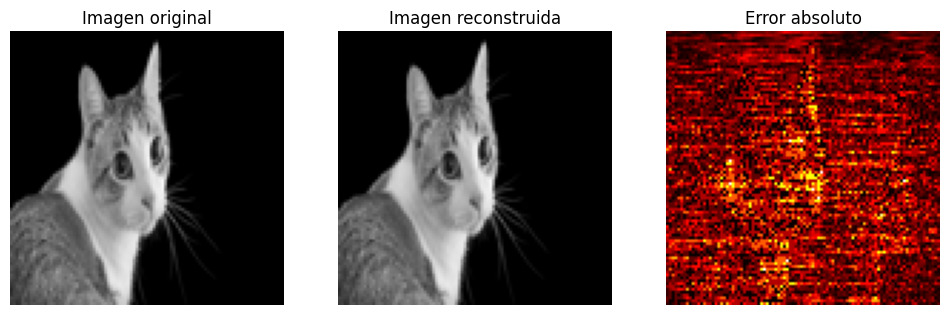

In [ ]:

imagen_recuperada = ifft2(F_scipy).real
error = np.abs(imagen-imagen_recuperada)

print('Error máximo:', np.max(error))
print('Error medio:', np.mean(error))

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(imagen, cmap='gray', vmin=0, vmax=1)
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(imagen_recuperada, cmap='gray', vmin=0, vmax=1)
plt.title('Imagen reconstruida')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(error, cmap='hot')
plt.title('Error absoluto')
plt.axis('off')
plt.show()

**Conclusión del ejercicio:** El espectro obtenido con el código de clase y el de SciPy tienen la misma distribución una vez corregida la normalización. La transformada inversa reconstruye la matriz original con un error numérico muy pequeño. La reconstrucción se compara con la versión en escala de grises y de 96 x 96, que fue la que se transformó.